<a href="https://colab.research.google.com/github/riiyu0410/DATA-ANALYSIS-USING-PYTHON-WITH-AUSPIFY/blob/main/DATA_ANALYSIS_USING_PYTHON_WITH_AUSPIFY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 1: Netflix Data Cleaning & Preparation

**Internship Program:** Data Analysis Using Python

**Organization:** Auspify Technologies

## Description
Prepare and organize the Netflix dataset for business analytics and reporting.

## Objective
The objective of this task is to import the Netflix dataset, identify and handle missing values, remove duplicate records and formatting inconsistencies, standardize important columns, and export the cleaned dataset for further analysis.

## Step 1: Import the Dataset

In this step, we import the required Python library, Pandas, and load the provided Netflix CSV dataset into a DataFrame. We display the first five rows and check the number of rows and columns to understand the dataset structure.

In [ ]:
import pandas as pd

# Load the provided Netflix dataset
df = pd.read_csv('Dataset (1).csv')

# Display the first five rows
display(df.head())

# Check dataset dimensions
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


Total Rows: 8790
Total Columns: 10


## Step 2: Identify and Handle Missing Values

In this step, we identify missing values in each column of the dataset. We then handle missing values using suitable replacements for relevant columns, while preserving available information wherever possible.

In [ ]:
# Count missing values in each column
print("Missing values before cleaning:")
print(df.isnull().sum())

# Display total missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Create a working copy
cleaned_df = df.copy()

# Handle missing values in selected columns
if 'country' in cleaned_df.columns:
    cleaned_df['country'] = cleaned_df['country'].fillna('Unknown')

if 'rating' in cleaned_df.columns:
    cleaned_df['rating'] = cleaned_df['rating'].fillna('Not Rated')

if 'director' in cleaned_df.columns:
    cleaned_df['director'] = cleaned_df['director'].fillna('Unknown')

# Verify missing values after handling selected columns
print("\nMissing values after handling selected columns:")
print(cleaned_df.isnull().sum())


Missing values before cleaning:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Total missing values: 0

Missing values after handling selected columns:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


## Step 3: Remove Duplicates and Formatting Inconsistencies

In this step, we identify and remove duplicate records. We also remove unnecessary spaces from text values and column names to maintain consistent formatting throughout the dataset.

In [ ]:
# Count duplicate records before removal
print("Duplicates before cleaning:",
      cleaned_df.duplicated().sum())

# Remove duplicate records
cleaned_df = cleaned_df.drop_duplicates().copy()

# Remove extra spaces from column names
cleaned_df.columns = cleaned_df.columns.str.strip()

# Clean extra spaces in text columns
for col in cleaned_df.select_dtypes(include='object').columns:
    cleaned_df[col] = cleaned_df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Verify the results
print("Duplicates after cleaning:",
      cleaned_df.duplicated().sum())

print("Updated dataset shape:", cleaned_df.shape)


Duplicates before cleaning: 0
Duplicates after cleaning: 0
Updated dataset shape: (8790, 10)


## Step 4: Standardize Country, Rating, and Type

In this step, we standardize the Country, Rating, and Type columns. We remove unnecessary spaces and apply consistent capitalization to the Type column. Missing values in Country and Rating are represented using clear labels.

In [ ]:
# Standardize Country column
if 'country' in cleaned_df.columns:
    cleaned_df['country'] = (
        cleaned_df['country'].fillna('Unknown').str.strip()
    )

# Standardize Rating column
if 'rating' in cleaned_df.columns:
    cleaned_df['rating'] = (
        cleaned_df['rating'].fillna('Not Rated').str.strip()
    )

# Standardize Type column
if 'type' in cleaned_df.columns:
    cleaned_df['type'] = (
        cleaned_df['type'].fillna('Unknown').str.strip().str.title()
    )

# Check standardized columns
for col in ['country', 'rating', 'type']:
    if col in cleaned_df.columns:
        print(f"\n{col.upper()} - Sample values:")
        print(cleaned_df[col].value_counts().head(10))


COUNTRY - Sample values:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

RATING - Sample values:
rating
TV-MA    3205
TV-14    2157
TV-PG     861
R         799
PG-13     490
TV-Y7     333
TV-Y      306
PG        287
TV-G      220
NR         79
Name: count, dtype: int64

TYPE - Sample values:
type
Movie      6126
Tv Show    2664
Name: count, dtype: int64


## Step 5: Export the Cleaned Dataset

After completing data cleaning and standardization, we export the prepared dataset to a new CSV file named `netflix_cleaned.csv`. This file will be used for subsequent data analysis tasks.

In [ ]:
# Export cleaned dataset
output_file = '/content/netflix_cleaned.csv'

cleaned_df.to_csv(output_file, index=False)

print("Cleaned dataset exported successfully!")
print("File name: netflix_cleaned.csv")
print("Final dataset shape:", cleaned_df.shape)

# Download the cleaned file
from google.colab import files
files.download(output_file)


Cleaned dataset exported successfully!
File name: netflix_cleaned.csv
Final dataset shape: (8790, 10)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

The Netflix dataset was imported successfully using Pandas. Missing values were identified and handled in selected columns. Duplicate records and unnecessary formatting inconsistencies were addressed, and the Country, Rating, and Type columns were standardized. Finally, the cleaned dataset was exported to a CSV file for further business analytics and reporting.

# Task 2: Content Type Analysis Dashboard

**Internship Program:** Data Analysis Using Python

**Organization:** Auspify Technologies

## Description
Analyze the distribution of Movies and TV Shows available on Netflix.

## Objective
The objective of this task is to analyze Netflix content by type, calculate the total number and percentage of Movies and TV Shows, create visualizations, and summarize the key findings.

### Step 1: Load the Cleaned Dataset

In this step, we load the Netflix dataset using the Pandas library. The dataset contains information about movies and TV shows, including their titles, content type, release year, rating, and country. We will use this data to analyze the distribution of Movies and TV Shows.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import io

# Upload the cleaned dataset
uploaded = files.upload()
filename = next(iter(uploaded))

# Load the dataset
df = pd.read_csv(io.BytesIO(uploaded[filename]))

# Remove spaces from column names
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("File name:", filename)
print("Dataset shape:", df.shape)

display(df.head())

Saving netflix_cleaned (1).csv to netflix_cleaned (1).csv
Dataset loaded successfully!
File name: netflix_cleaned (1).csv
Dataset shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## Step 2: Calculate the Total Number of Movies and TV Shows

In this step, we calculate the total number of Movies and TV Shows using Pandas. The `value_counts()` function counts the records belonging to each content type. We standardize the text to lowercase to avoid counting errors caused by differences in capitalization, such as `TV Show` and `Tv Show`.

In [3]:
# Standardize content type
df['type'] = df['type'].astype(str).str.strip().str.lower()

# Count each content type
content_counts = df['type'].value_counts()

print("Content Type Distribution:")
print(content_counts)

movies = content_counts.get('movie', 0)
tv_shows = content_counts.get('tv show', 0)
total_content = movies + tv_shows

print("\nTotal Movies:", movies)
print("Total TV Shows:", tv_shows)
print("Total Content:", total_content)

Content Type Distribution:
type
movie      6126
tv show    2664
Name: count, dtype: int64

Total Movies: 6126
Total TV Shows: 2664
Total Content: 8790


### Step 3: Visualize Content Distribution

In this step, we use Matplotlib and Seaborn to create a bar chart and a pie chart. The bar chart compares the number of Movies and TV Shows, while the pie chart displays their percentage distribution.

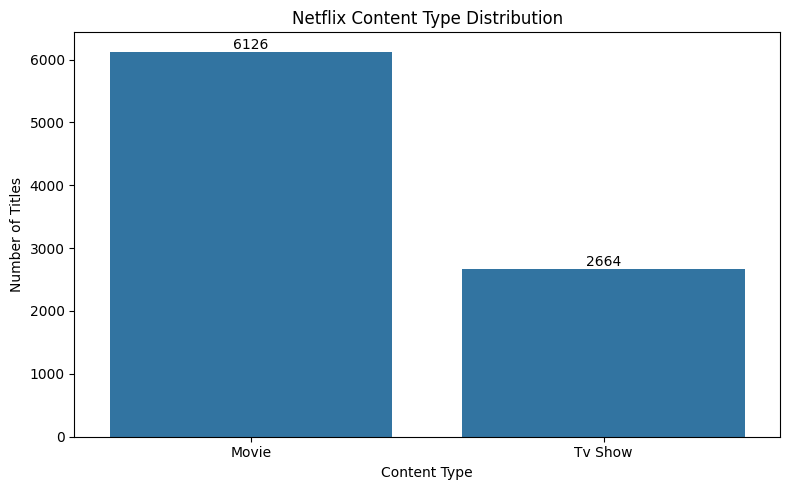

In [ ]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=content_counts.index,
    y=content_counts.values
)

plt.title("Netflix Content Type Distribution")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

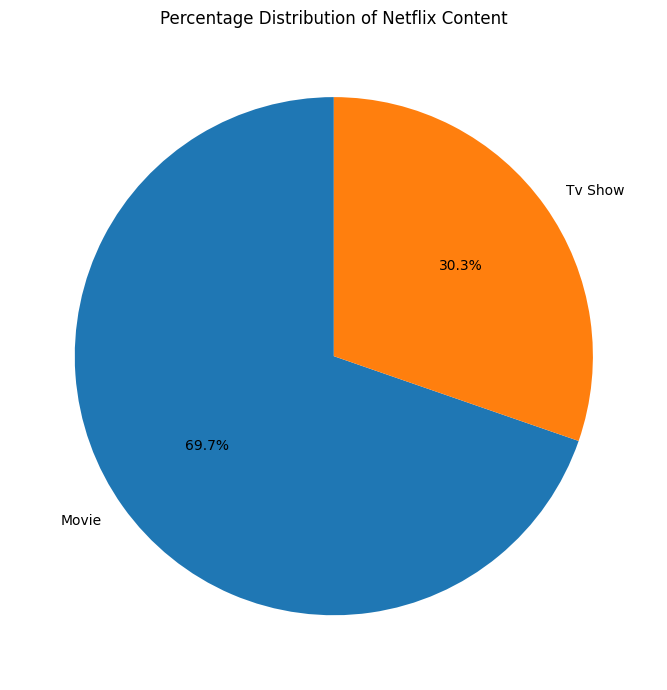

In [ ]:
plt.figure(figsize=(7, 7))

plt.pie(
    content_counts.values,
    labels=content_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Percentage Distribution of Netflix Content")
plt.tight_layout()
plt.show()

## Step 4: Compare Content Proportions

In this step, we calculate the percentage of Movies and TV Shows in the dataset. The percentage is calculated by dividing the number of titles in each category by the total number of titles and multiplying the result by 100. This comparison helps identify which content type has the larger share.

In [4]:
total = content_counts.sum()

content_percentages = (content_counts / total) * 100

print("Content Type Percentages:")

for content_type, percentage in content_percentages.items():
    print(f"{content_type.title()}: {percentage:.2f}%")

Content Type Percentages:
Movie: 69.69%
Tv Show: 30.31%


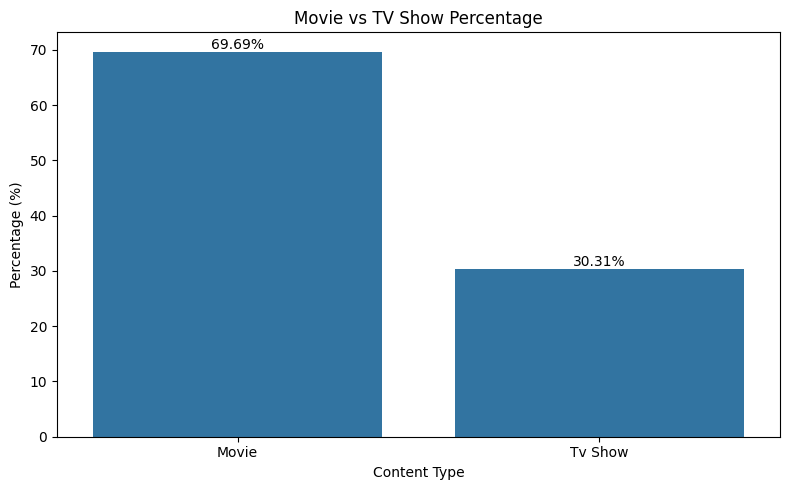

In [5]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=content_percentages.index.str.title(),
    y=content_percentages.values
)

plt.title("Movie vs TV Show Percentage")
plt.xlabel("Content Type")
plt.ylabel("Percentage (%)")

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%')

plt.tight_layout()
plt.show()

## Step 5: Key Findings and Summary Report

### Key Findings

1. The dataset contains a total of **8,790 titles**.
2. There are **6,126 Movies**, representing approximately **69.69%** of the dataset.
3. There are **2,664 TV Shows**, representing approximately **30.31%** of the dataset.
4. Movies account for the larger proportion of the provided Netflix dataset.
5. The bar chart compares the total number of titles in each category.
6. The pie chart displays the percentage distribution of Movies and TV Shows.
7. Pandas, Matplotlib, and Seaborn help analyze and visualize the content distribution.

### Conclusion

The Content Type Analysis Dashboard successfully analyzes the distribution of Movies and TV Shows in the provided Netflix dataset. The results show that Movies form the majority of the dataset. The visualizations and percentage calculations make the distribution easy to understand and demonstrate the use of Python for exploratory data analysis.

##Task 3: Country-Wise Netflix Content Analysis

## Step 1: Extract and Clean Country Information

In this step, we examine the `country` column and handle missing or unavailable country information. Some Netflix titles are associated with multiple countries separated by commas. We split these country names so that each country can be analyzed separately.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import io

# Upload the cleaned dataset
uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving netflix_cleaned.csv to netflix_cleaned.csv
Dataset loaded successfully!
Dataset shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [7]:
# Check country information
print("Missing country values:", df['country'].isnull().sum())

print("\nMost common country entries:")
print(df['country'].value_counts().head(10))

# Replace missing and blank country values
df['country'] = (
    df['country']
    .fillna('Unknown')
    .astype(str)
    .str.strip()
    .replace('', 'Unknown')
)

# Split multiple countries into separate rows
country_df = df.assign(
    country=df['country'].str.split(',')
).explode('country')

# Clean spaces around each country name
country_df['country'] = country_df['country'].str.strip()

# Remove records without usable country information
country_df = country_df[
    (country_df['country'] != '') &
    (country_df['country'].str.lower() != 'unknown') &
    (country_df['country'].str.lower() != 'not given')
].copy()

print("\nCountry information cleaned successfully!")
print("Country-title rows:", len(country_df))
print("Unique countries:", country_df['country'].nunique())

display(country_df[['title', 'country']].head(10))

Missing country values: 0

Most common country entries:
country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64

Country information cleaned successfully!
Country-title rows: 8503
Unique countries: 85


,title,country
0,Dick Johnson Is Dead,United States
1,Ganglands,France
2,Midnight Mass,United States
3,Confessions of an Invisible Girl,Brazil
4,Sankofa,United States
5,The Great British Baking Show,United Kingdom
6,The Starling,United States
7,Motu Patlu in the Game of Zones,India
8,Je Suis Karl,Germany
9,Motu Patlu in Wonderland,India


## Step 2: Calculate Content Count by Country

In this step, we use Pandas GroupBy and aggregation operations to calculate how many Netflix titles are associated with each country. The results help us compare country-wise content representation in the dataset.

In [8]:
# Count titles associated with each country
country_counts = (
    country_df.groupby('country')['show_id']
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 Countries by Netflix Title Count:")
display(country_counts.head(10).reset_index(name='Total Titles'))

Top 10 Countries by Netflix Title Count:


,country,Total Titles
0,United States,3240
1,India,1057
2,United Kingdom,638
3,Pakistan,421
4,Canada,271
5,Japan,259
6,South Korea,214
7,France,213
8,Spain,182
9,Mexico,138


## Step 3: Identify Top Content-Producing Countries

In this step, we rank countries according to the number of distinct Netflix titles associated with them. The top 10 countries are selected to identify which countries have the highest representation in the provided dataset.

In [9]:
# Select top 10 countries
top_10_countries = country_counts.head(10)

# Display ranking report
ranking_report = top_10_countries.reset_index()
ranking_report.index = ranking_report.index + 1
ranking_report.index.name = 'Rank'
ranking_report = ranking_report.rename(
    columns={'show_id': 'Total Titles'}
)

print("Country-Wise Ranking Report:")
display(ranking_report)

Country-Wise Ranking Report:


,country,Total Titles
Rank,,
1,United States,3240
2,India,1057
3,United Kingdom,638
4,Pakistan,421
5,Canada,271
6,Japan,259
7,South Korea,214
8,France,213
9,Spain,182


## Step 4: Create Charts and Rankings

In this step, we create a horizontal bar chart to visualize the top 10 countries by Netflix title count. The chart makes country-wise comparisons easier and highlights the countries with the largest number of titles associated with them.

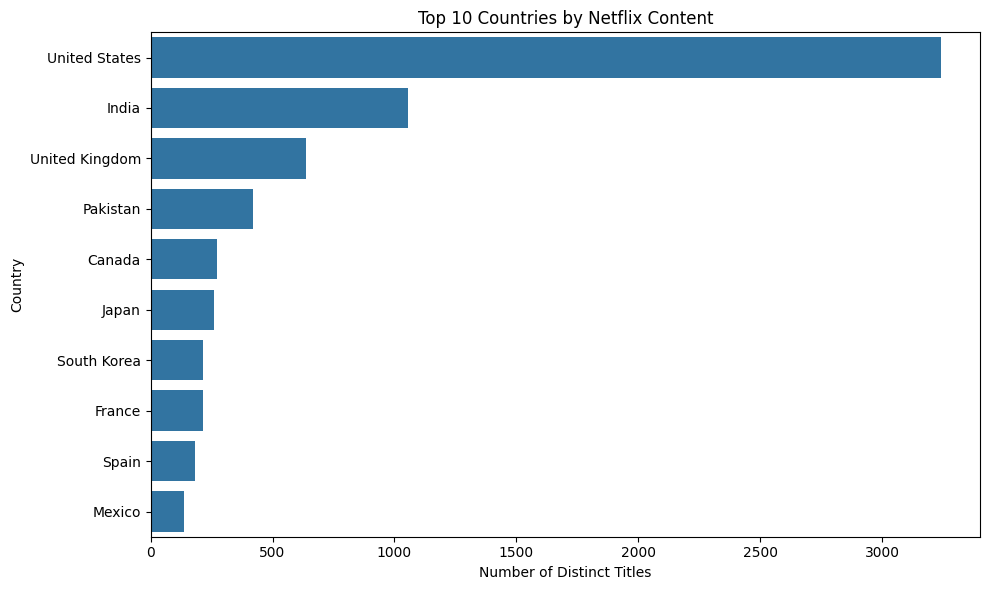

In [10]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_10_countries.values,
    y=top_10_countries.index
)

plt.title("Top 10 Countries by Netflix Content")
plt.xlabel("Number of Distinct Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

### Country-Wise Content Share

This visualization shows the percentage share of titles associated with the top 10 countries relative to all country-title associations in the cleaned country analysis. Since a title may be associated with multiple countries, these percentages are based on country-title associations, not on unique Netflix titles overall.

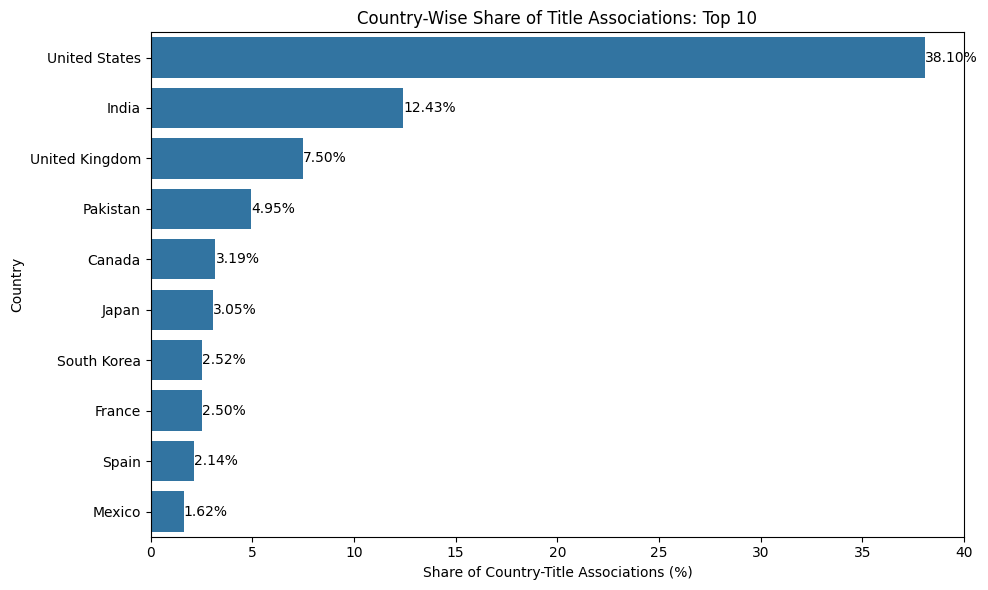

In [11]:
top_country_percentages = (
    top_10_countries / country_counts.sum()
) * 100

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=top_country_percentages.values,
    y=top_country_percentages.index
)

plt.title("Country-Wise Share of Title Associations: Top 10")
plt.xlabel("Share of Country-Title Associations (%)")
plt.ylabel("Country")

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%')

plt.tight_layout()
plt.show()

## Step 5: Business Insights

Country-wise analysis helps understand the geographic representation of content in the Netflix dataset. The rankings and charts can help identify countries with a high number of associated titles and support further analysis of content distribution.

### Business Applications
1. Identify countries with the highest representation in the dataset.
2. Compare content representation across countries.
3. Explore geographic patterns in Netflix's catalog.
4. Support decisions about further regional content analysis.
5. Identify countries that may need more detailed investigation.

### Limitations
A title may be associated with more than one country. Therefore, country counts represent titles associated with each country, and adding counts across countries may count a title more than once. The results describe the provided dataset and do not necessarily reflect Netflix's current catalog or actual production volume in each country.

In [12]:
print("COUNTRY-WISE NETFLIX CONTENT ANALYSIS")
print("=" * 45)

print("Total distinct titles in dataset:", df['show_id'].nunique())
print("Countries identified:", country_df['country'].nunique())

if not country_counts.empty:
    top_country = country_counts.index[0]
    top_count = country_counts.iloc[0]

    print(f"\nCountry with the highest title count: {top_country}")
    print(f"Number of associated titles: {top_count}")

    print("\nTop 5 Countries:")
    for rank, (country, count) in enumerate(
        country_counts.head(5).items(), start=1
    ):
        print(f"{rank}. {country}: {count} titles")

print("\nBusiness Insight:")
print(
    "The ranking identifies countries with the highest "
    "representation in the provided Netflix dataset."
)

COUNTRY-WISE NETFLIX CONTENT ANALYSIS
Total distinct titles in dataset: 8790
Countries identified: 85

Country with the highest title count: United States
Number of associated titles: 3240

Top 5 Countries:
1. United States: 3240 titles
2. India: 1057 titles
3. United Kingdom: 638 titles
4. Pakistan: 421 titles
5. Canada: 271 titles

Business Insight:
The ranking identifies countries with the highest representation in the provided Netflix dataset.


##Task 4: Trend Analysis by Release Year
## Step 1: Load and Organize the Dataset by Release Year

In this step, we load the cleaned Netflix dataset using Pandas. We check the `release_year` column, handle invalid or missing year values, and prepare the data for yearly trend analysis.

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import io

# Upload the cleaned dataset
uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving netflix_cleaned.csv to netflix_cleaned (2).csv
Dataset loaded successfully!
Dataset shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [14]:
# Convert release_year to numeric
df['release_year'] = pd.to_numeric(
    df['release_year'], errors='coerce'
)

# Remove rows with missing or invalid release years
year_df = df.dropna(subset=['release_year']).copy()

year_df['release_year'] = year_df['release_year'].astype(int)

print("Original dataset rows:", len(df))
print("Rows with valid release years:", len(year_df))
print("Year range:",
      year_df['release_year'].min(),
      "to",
      year_df['release_year'].max())

display(year_df[['title', 'type', 'release_year']].head())

Original dataset rows: 8790
Rows with valid release years: 8790
Year range: 1925 to 2021


,title,type,release_year
0,Dick Johnson Is Dead,Movie,2020
1,Ganglands,Tv Show,2021
2,Midnight Mass,Tv Show,2021
3,Confessions of an Invisible Girl,Movie,2021
4,Sankofa,Movie,1993


## Step 2: Calculate Yearly Content Releases

In this step, we group Netflix titles by `release_year` and count the number of titles associated with each year. The yearly counts help us understand how the distribution of content has changed over time.

In [15]:
yearly_counts = (
    year_df.groupby('release_year')['show_id']
    .nunique()
    .sort_index()
)

yearly_report = yearly_counts.reset_index()
yearly_report.columns = ['Release Year', 'Number of Titles']

print("Yearly Content Release Report:")
display(yearly_report.tail(15))

Yearly Content Release Report:


,Release Year,Number of Titles
59,2007,88
60,2008,135
61,2009,152
62,2010,192
63,2011,185
64,2012,236
65,2013,286
66,2014,352
67,2015,555
68,2016,901


In [16]:
yearly_type_counts = (
    year_df.groupby(['release_year', 'type'])['show_id']
    .nunique()
    .unstack(fill_value=0)
    .sort_index()
)

print("Yearly Distribution by Content Type:")
display(yearly_type_counts.tail(15))

Yearly Distribution by Content Type:


type,Movie,Tv Show
release_year,,
2007,74,14
2008,113,22
2009,118,34
2010,153,39
2011,145,40
2012,173,63
2013,225,61
2014,264,88
2015,396,159


## Step 3: Identify Growth and Decline Trends

In this step, we calculate the year-over-year change in the number of titles. The absolute change shows how many titles were added or reduced compared with the previous year in the dataset. The percentage change shows the relative increase or decrease.

In [17]:
trend_df = yearly_counts.to_frame(name='Total Titles')

trend_df['Yearly Change'] = trend_df['Total Titles'].diff()

trend_df['Growth Percentage'] = (
    trend_df['Total Titles']
    .pct_change(fill_method=None) * 100
)

print("Yearly Growth and Decline Report:")
display(trend_df.tail(15).round(2))

Yearly Growth and Decline Report:


,Total Titles,Yearly Change,Growth Percentage
release_year,,,
2007,88,-8.0,-8.33
2008,135,47.0,53.41
2009,152,17.0,12.59
2010,192,40.0,26.32
2011,185,-7.0,-3.65
2012,236,51.0,27.57
2013,286,50.0,21.19
2014,352,66.0,23.08
2015,555,203.0,57.67


In [18]:
peak_year = yearly_counts.idxmax()
peak_count = yearly_counts.max()

lowest_year = yearly_counts.idxmin()
lowest_count = yearly_counts.min()

print("Year with Highest Title Count:", peak_year)
print("Number of Titles:", peak_count)

print("\nYear with Lowest Title Count:", lowest_year)
print("Number of Titles:", lowest_count)

Year with Highest Title Count: 2018
Number of Titles: 1146

Year with Lowest Title Count: 1925
Number of Titles: 1


## Step 4: Create Trend Visualizations

In this step, we use Matplotlib and Seaborn to visualize yearly content counts. A line chart highlights changes over time, while a separate chart compares Movies and TV Shows by release year.

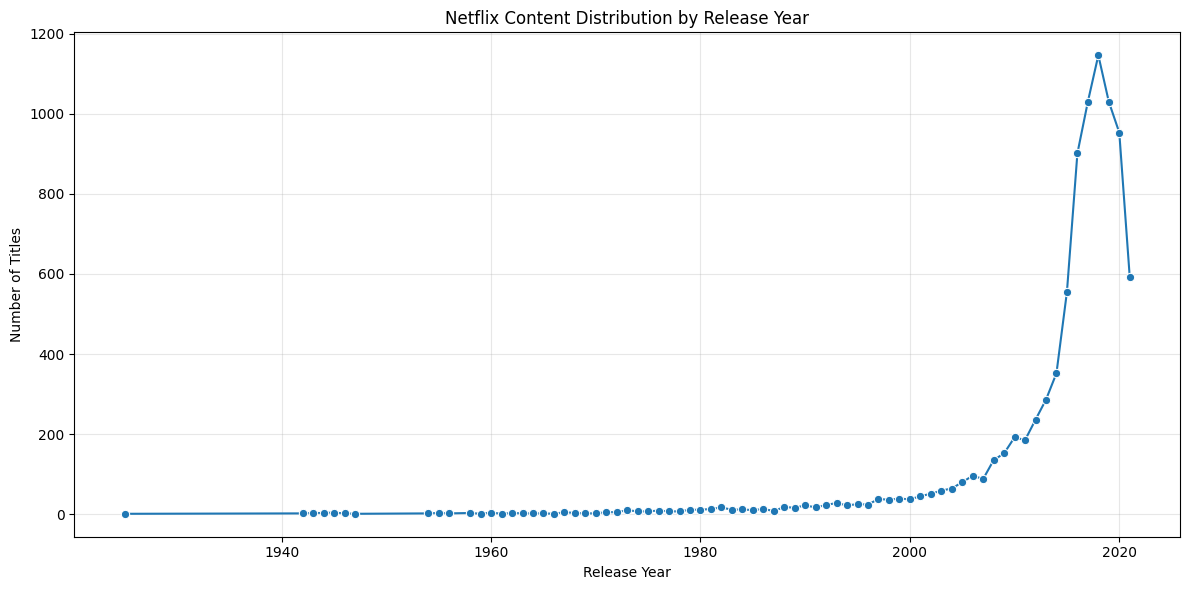

In [19]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    x=yearly_counts.index,
    y=yearly_counts.values,
    marker='o'
)

plt.title("Netflix Content Distribution by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

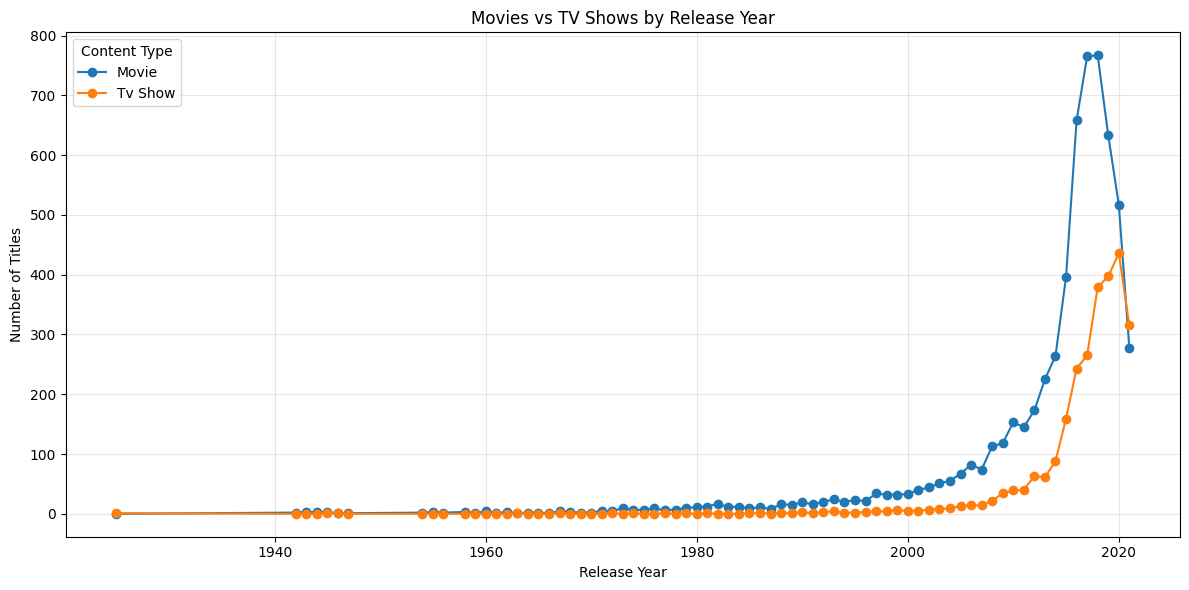

In [20]:
plt.figure(figsize=(12, 6))

for content_type in yearly_type_counts.columns:
    plt.plot(
        yearly_type_counts.index,
        yearly_type_counts[content_type],
        marker='o',
        label=content_type
    )

plt.title("Movies vs TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend(title="Content Type")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

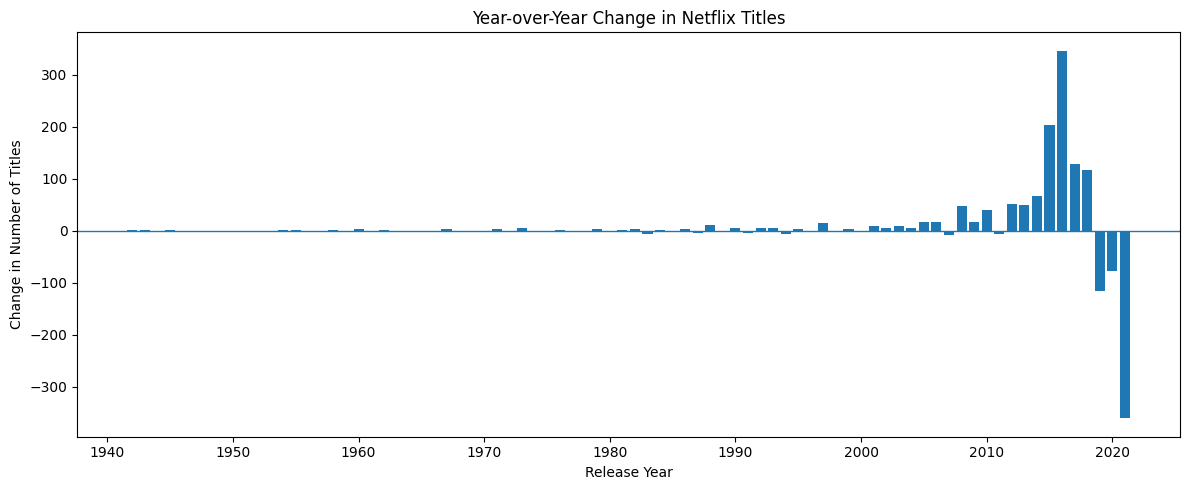

In [21]:
growth_data = trend_df.dropna(subset=['Yearly Change'])

plt.figure(figsize=(12, 5))

plt.bar(
    growth_data.index,
    growth_data['Yearly Change']
)

plt.axhline(0, linewidth=1)
plt.title("Year-over-Year Change in Netflix Titles")
plt.xlabel("Release Year")
plt.ylabel("Change in Number of Titles")
plt.tight_layout()
plt.show()

## Step 5: Business Insights and Interpretation

Year-wise analysis helps identify historical patterns in the Netflix dataset. It shows which release years have higher or lower title counts and how the number of represented titles changes between consecutive years.

### Business Applications
1. Identify release years with a high number of titles.
2. Compare the historical representation of Movies and TV Shows.
3. Observe year-over-year increases and decreases.
4. Support further analysis of content catalog trends.
5. Help analysts investigate changes in the types of content represented.

### Limitations
The release year indicates when a title was originally released, not necessarily when Netflix added it to its platform. The dataset represents a particular catalog snapshot, so its yearly counts should not be treated as complete worldwide production statistics or proof of Netflix's actual annual production rate.

In [22]:
print("NETFLIX RELEASE YEAR TREND ANALYSIS")
print("=" * 45)

print("Total distinct titles analyzed:", year_df['show_id'].nunique())
print("Release year range:",
      year_df['release_year'].min(),
      "to",
      year_df['release_year'].max())

print(f"\nHighest title count: {peak_count} titles in {peak_year}")
print(f"Lowest title count: {lowest_count} titles in {lowest_year}")

if len(yearly_counts) >= 2:
    first_year = yearly_counts.index[0]
    last_year = yearly_counts.index[-1]

    print(f"\nFirst year in report: {first_year} "
          f"({yearly_counts.iloc[0]} titles)")
    print(f"Last year in report: {last_year} "
          f"({yearly_counts.iloc[-1]} titles)")

print("\nBusiness Insight:")
print(
    "The charts show how the release-year distribution of titles "
    "varies across the years represented in the dataset."
)

NETFLIX RELEASE YEAR TREND ANALYSIS
Total distinct titles analyzed: 8790
Release year range: 1925 to 2021

Highest title count: 1146 titles in 2018
Lowest title count: 1 titles in 1925

First year in report: 1925 (1 titles)
Last year in report: 2021 (592 titles)

Business Insight:
The charts show how the release-year distribution of titles varies across the years represented in the dataset.


##Task 5: Content Rating & Genre Analysis
## Step 1: Analyze Content Rating Categories

In this step, we load the cleaned Netflix dataset and examine the `rating` column. We calculate the number of titles in each rating category to understand how content is distributed across different audience classifications.

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import io

# Upload the cleaned dataset
uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving netflix_cleaned.csv to netflix_cleaned (3).csv
Dataset loaded successfully!
Dataset shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [24]:
# Clean rating values
df['rating'] = (
    df['rating']
    .fillna('Not Rated')
    .astype(str)
    .str.strip()
    .replace('', 'Not Rated')
)

# Count titles in each rating category
rating_counts = df['rating'].value_counts()

print("Content Rating Distribution:")
display(rating_counts.reset_index(name='Number of Titles'))

Content Rating Distribution:


,rating,Number of Titles
0,TV-MA,3205
1,TV-14,2157
2,TV-PG,861
3,R,799
4,PG-13,490
5,TV-Y7,333
6,TV-Y,306
7,PG,287
8,TV-G,220
9,NR,79


### Rating Distribution Visualization

A horizontal bar chart is created to compare the number of titles in different rating categories. This helps identify which ratings appear most frequently in the dataset.

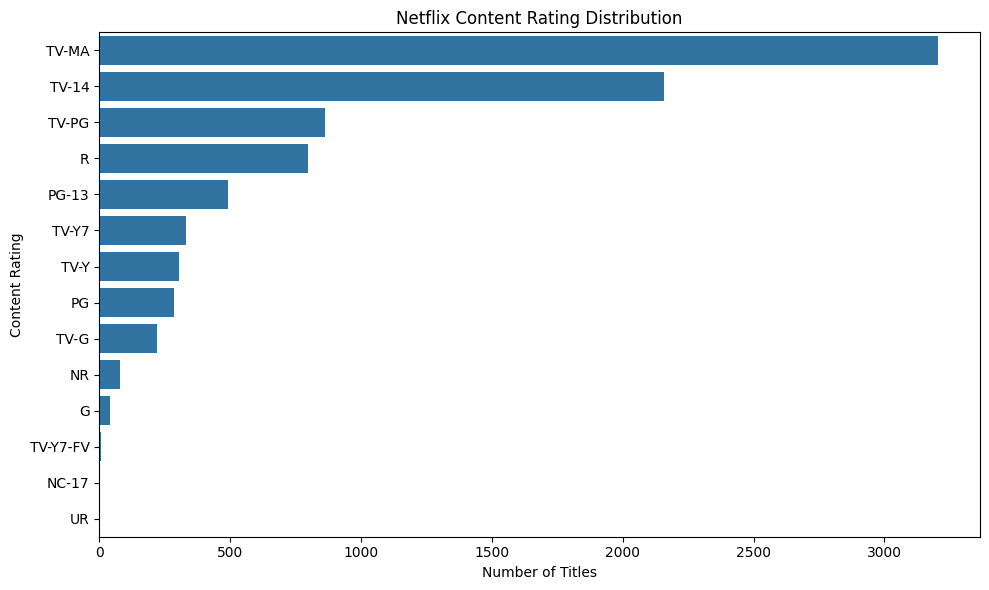

In [25]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=rating_counts.values,
    y=rating_counts.index
)

plt.title("Netflix Content Rating Distribution")
plt.xlabel("Number of Titles")
plt.ylabel("Content Rating")
plt.tight_layout()
plt.show()

## Step 2: Identify the Most Common Genres

In this step, we analyze the `listed_in` column, which contains genre or category labels. Some titles have multiple genres separated by commas. We split these labels and count how frequently each genre appears in the dataset.

In [26]:
# Prepare genre information
genre_df = df[['show_id', 'listed_in']].copy()

genre_df['listed_in'] = (
    genre_df['listed_in']
    .fillna('')
    .astype(str)
    .str.strip()
)

# Split multiple genre labels into separate rows
genre_df['genre'] = genre_df['listed_in'].str.split(',')

genre_df = genre_df.explode('genre')
genre_df['genre'] = genre_df['genre'].str.strip()

# Remove blank genre values
genre_df = genre_df[genre_df['genre'] != '']

# Count distinct titles per genre
genre_counts = (
    genre_df.groupby('genre')['show_id']
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 Most Common Genres:")
display(genre_counts.head(10).reset_index(name='Number of Titles'))

Top 10 Most Common Genres:


,genre,Number of Titles
0,International Movies,2752
1,Dramas,2426
2,Comedies,1674
3,International TV Shows,1349
4,Documentaries,869
5,Action & Adventure,859
6,TV Dramas,762
7,Independent Movies,756
8,Children & Family Movies,641
9,Romantic Movies,616


### Most Common Genres Visualization

A horizontal bar chart displays the ten most common genres. It provides a clear comparison of the number of titles associated with each genre.

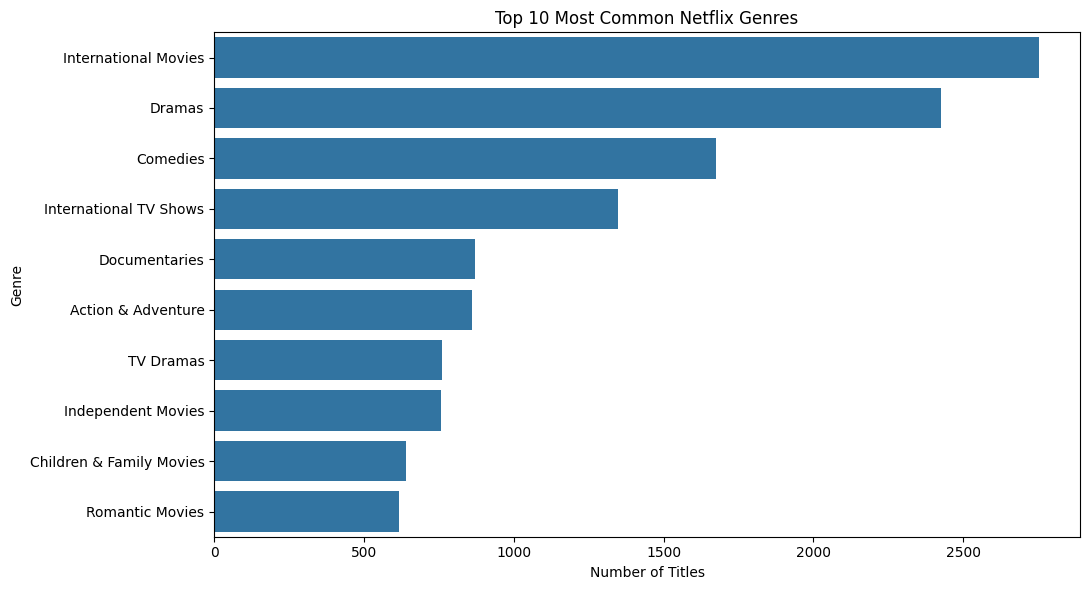

In [27]:
top_genres = genre_counts.head(10)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Most Common Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

## Step 3: Compare Ratings Across Content Types

In this step, we compare content ratings for Movies and TV Shows. Grouping the dataset by content type and rating helps us understand how rating categories are distributed across the two types of content.

In [28]:
# Standardize content type
df['type'] = (
    df['type']
    .astype(str)
    .str.strip()
    .str.lower()
)

# Create a cross-tabulation of content type and rating
rating_comparison = pd.crosstab(
    df['rating'],
    df['type']
)

print("Rating Comparison: Movies vs TV Shows")
display(rating_comparison)

Rating Comparison: Movies vs TV Shows


type,movie,tv show
rating,,
G,41,0
NC-17,3,0
NR,75,4
PG,287,0
PG-13,490,0
R,797,2
TV-14,1427,730
TV-G,126,94
TV-MA,2062,1143


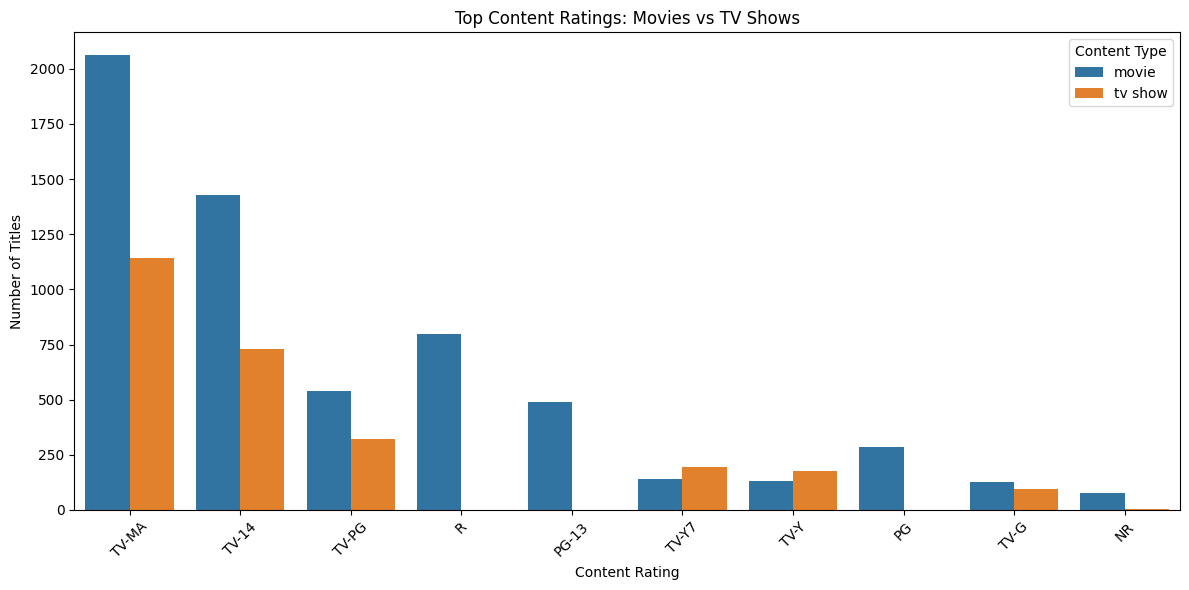

In [29]:
# Keep the most common rating categories for readability
top_ratings = df['rating'].value_counts().head(10).index

comparison_data = df[df['rating'].isin(top_ratings)]

plt.figure(figsize=(12, 6))

sns.countplot(
    data=comparison_data,
    x='rating',
    hue='type',
    order=top_ratings
)

plt.title("Top Content Ratings: Movies vs TV Shows")
plt.xlabel("Content Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()

## Step 4: Interactive Rating and Genre Exploration

In this step, we create an interactive visualization using Plotly. Users can hover over the bars to view values and select different content types to explore rating distributions. This makes the analysis more engaging and easier to interpret.

In [30]:
import plotly.express as px

# Create an interactive chart
interactive_rating = (
    df.groupby(['type', 'rating'])['show_id']
    .nunique()
    .reset_index(name='Number of Titles')
)

fig = px.bar(
    interactive_rating,
    x='rating',
    y='Number of Titles',
    color='type',
    barmode='group',
    title='Interactive Content Rating Comparison',
    labels={
        'rating': 'Content Rating',
        'Number of Titles': 'Number of Titles',
        'type': 'Content Type'
    },
    hover_data=['Number of Titles']
)

fig.update_layout(
    xaxis_tickangle=-45,
    template='plotly_white'
)

fig.show()

In [31]:
interactive_genres = (
    genre_df.groupby('genre')['show_id']
    .nunique()
    .reset_index(name='Number of Titles')
    .sort_values('Number of Titles', ascending=False)
    .head(15)
)

fig = px.bar(
    interactive_genres,
    x='Number of Titles',
    y='genre',
    orientation='h',
    title='Interactive Top 15 Netflix Genres',
    labels={
        'genre': 'Genre',
        'Number of Titles': 'Number of Titles'
    },
    hover_data=['Number of Titles']
)

fig.update_layout(
    yaxis={'categoryorder': 'total ascending'},
    template='plotly_white'
)

fig.show()

## Step 5: Audience Insights and Business Interpretation

### Key Insights
1. Rating analysis shows how titles are distributed across content rating categories.
2. Genre analysis identifies the most frequently represented genres.
3. Comparing Movies and TV Shows reveals differences in their rating distributions.
4. Interactive charts make it easier to explore individual categories.
5. These results can help analysts understand the types of content represented in the dataset.

### Business Applications
- Explore content categories that have high representation.
- Compare the rating profiles of Movies and TV Shows.
- Support further audience-segmentation research.
- Identify genre categories for deeper analysis.
- Help guide additional content-catalog research.

### Limitation
Content ratings indicate classification categories, not actual viewer age, preferences, or viewing behavior. The dataset does not directly prove audience demand or popularity. The findings describe only the provided dataset.

In [32]:
print("CONTENT RATING & GENRE ANALYSIS")
print("=" * 40)

print("\nTotal distinct titles:", df['show_id'].nunique())

print("\nTop 5 Content Ratings:")
display(rating_counts.head(5).reset_index(name='Number of Titles'))

print("\nTop 5 Genres:")
display(genre_counts.head(5).reset_index(name='Number of Titles'))

print("\nContent Type Distribution:")
print(df['type'].value_counts())

print("\nBusiness Insight:")
print(
    "Rating and genre analysis helps describe the content categories "
    "represented in the dataset. These patterns can support further "
    "audience research, but they do not directly measure audience demand."
)

CONTENT RATING & GENRE ANALYSIS

Total distinct titles: 8790

Top 5 Content Ratings:


,rating,Number of Titles
0,TV-MA,3205
1,TV-14,2157
2,TV-PG,861
3,R,799
4,PG-13,490



Top 5 Genres:


,genre,Number of Titles
0,International Movies,2752
1,Dramas,2426
2,Comedies,1674
3,International TV Shows,1349
4,Documentaries,869



Content Type Distribution:
type
movie      6126
tv show    2664
Name: count, dtype: int64

Business Insight:
Rating and genre analysis helps describe the content categories represented in the dataset. These patterns can support further audience research, but they do not directly measure audience demand.


##Task 6: Netflix Business Insights Report
## Step 1: Load the Dataset and Perform Exploratory Data Analysis

In this step, we load the cleaned Netflix dataset and examine its structure, columns, data types, missing values, duplicate records, and descriptive statistics. This helps us understand the quality and characteristics of the data before generating business insights.

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
import io

# Upload cleaned dataset
uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(io.BytesIO(uploaded[filename]))
df.columns = df.columns.str.strip()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving netflix_cleaned.csv to netflix_cleaned (4).csv
Dataset loaded successfully!
Dataset shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,Tv Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,Tv Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [34]:
print("DATASET INFORMATION")
print("=" * 40)

print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDescriptive statistics:")
display(df.describe(include="all").T)

DATASET INFORMATION

Number of rows: 8790
Number of columns: 10

Column names:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Data types:
show_id         object
type            object
title           object
director        object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
dtype: object

Missing values:


,Missing Values
show_id,0
type,0
title,0
director,0
country,0
date_added,0
release_year,0
rating,0
duration,0
listed_in,0



Duplicate rows: 0

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8790,8790,s8786,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8790,2,Movie,6126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8790,8786,9-Feb,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,8790,4528,Not Given,2588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,8790,86,United States,3240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8790,1713,1/1/2020,110,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8790.0,NaN,NaN,NaN,2014.183163,8.825466,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8790,14,TV-MA,3205,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8790,220,1 Season,1791,NaN,NaN,NaN,NaN,NaN,NaN,NaN
listed_in,8790,513,"Dramas, International Movies",362,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Data Quality and Preparation

The dataset is checked for missing values, duplicate records, and inconsistent formatting. The `type`, `country`, `rating`, `release_year`, and `listed_in` columns are prepared for further analysis. Missing information is represented using clear labels where appropriate.

In [35]:
# Work on a copy of the dataset
analysis_df = df.copy()

# Remove duplicate records
analysis_df = analysis_df.drop_duplicates().copy()

# Clean text columns
for col in analysis_df.select_dtypes(include="object").columns:
    analysis_df[col] = analysis_df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Standardize content type
analysis_df["type"] = (
    analysis_df["type"].astype(str).str.strip().str.lower()
)

# Standardize missing labels
for col in ["country", "rating", "listed_in", "director"]:
    if col in analysis_df.columns:
        analysis_df[col] = (
            analysis_df[col]
            .fillna("Unknown")
            .astype(str)
            .str.strip()
            .replace("", "Unknown")
        )

# Convert release year to numeric
analysis_df["release_year"] = pd.to_numeric(
    analysis_df["release_year"], errors="coerce"
)

print("Analysis dataset prepared.")
print("Rows:", len(analysis_df))
print("Missing values remaining:")
display(analysis_df.isnull().sum().to_frame("Missing Values"))

Analysis dataset prepared.
Rows: 8790
Missing values remaining:


,Missing Values
show_id,0
type,0
title,0
director,0
country,0
date_added,0
release_year,0
rating,0
duration,0
listed_in,0


## Step 2: Analyze Key Content Trends and Patterns

In this step, we analyze content type, release year, ratings, and countries. These dimensions help describe the composition of the Netflix dataset and identify patterns that can be investigated further for business planning.

Content Type Distribution:


,type,Number of Titles
0,movie,6126
1,tv show,2664


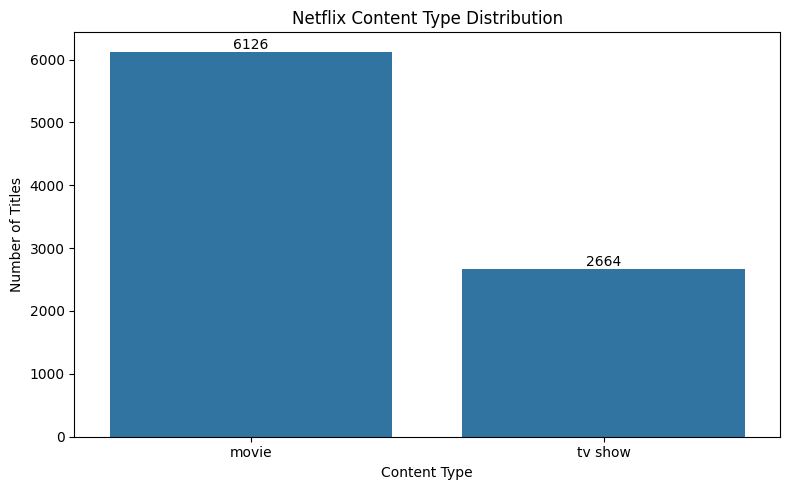

In [36]:
content_counts = analysis_df["type"].value_counts()

print("Content Type Distribution:")
display(content_counts.reset_index(name="Number of Titles"))

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=content_counts.index,
    y=content_counts.values
)
plt.title("Netflix Content Type Distribution")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")

for container in ax.containers:
    ax.bar_label(container)

plt.tight_layout()
plt.show()

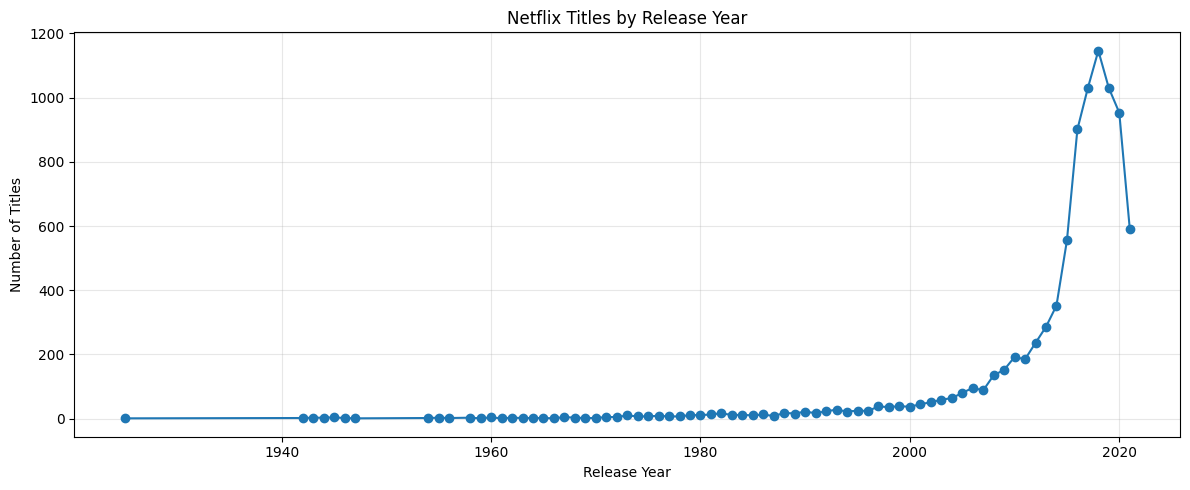

Year with the highest title count: 2018
Highest count: 1146


In [37]:
year_df = analysis_df.dropna(subset=["release_year"]).copy()
year_df["release_year"] = year_df["release_year"].astype(int)

yearly_counts = (
    year_df.groupby("release_year")["show_id"]
    .nunique()
    .sort_index()
)

plt.figure(figsize=(12, 5))
plt.plot(yearly_counts.index, yearly_counts.values, marker="o")
plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Year with the highest title count:", yearly_counts.idxmax())
print("Highest count:", yearly_counts.max())

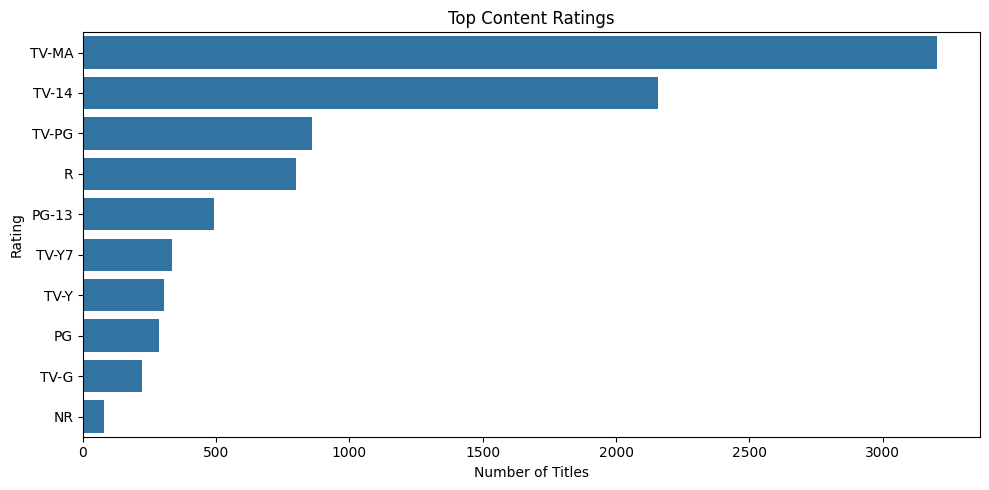

,rating,Number of Titles
0,TV-MA,3205
1,TV-14,2157
2,TV-PG,861
3,R,799
4,PG-13,490
5,TV-Y7,333
6,TV-Y,306
7,PG,287
8,TV-G,220
9,NR,79


In [38]:
rating_counts = analysis_df["rating"].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=rating_counts.values, y=rating_counts.index)
plt.title("Top Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

display(rating_counts.reset_index(name="Number of Titles"))

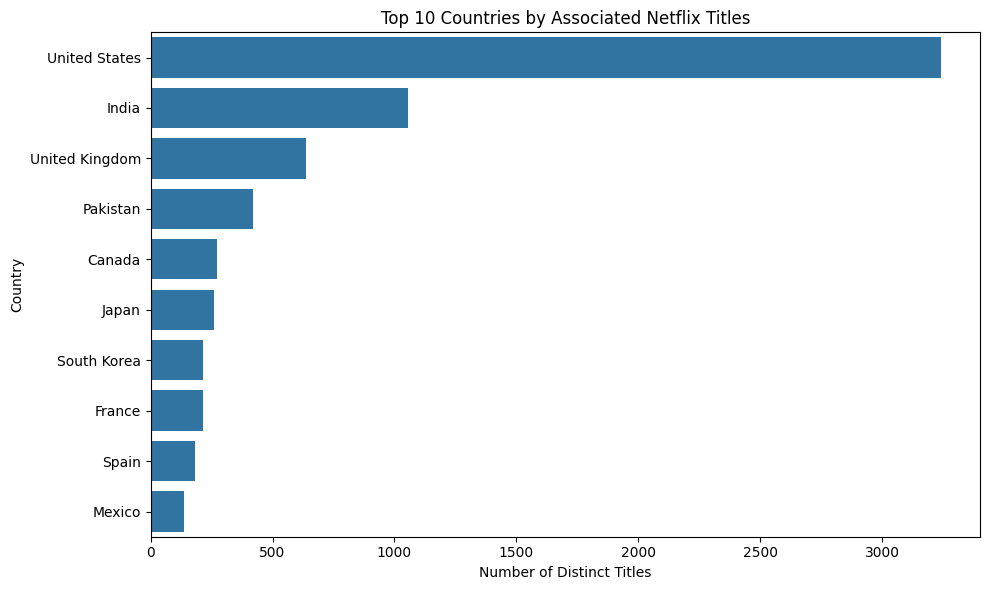

,country,Number of Titles
0,United States,3240
1,India,1057
2,United Kingdom,638
3,Pakistan,421
4,Canada,271
5,Japan,259
6,South Korea,214
7,France,213
8,Spain,182
9,Mexico,138


In [39]:
# Split titles associated with multiple countries
country_df = analysis_df[["show_id", "country"]].copy()

country_df["country"] = country_df["country"].str.split(",")
country_df = country_df.explode("country")
country_df["country"] = country_df["country"].str.strip()

# Exclude unavailable country labels
country_df = country_df[
    ~country_df["country"].str.lower().isin(
        ["unknown", "not given", ""]
    )
]

country_counts = (
    country_df.groupby("country")["show_id"]
    .nunique()
    .sort_values(ascending=False)
)

top_countries = country_counts.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 Countries by Associated Netflix Titles")
plt.xlabel("Number of Distinct Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

display(top_countries.reset_index(name="Number of Titles"))

## Step 3: Develop a Business Intelligence Dashboard

In this step, we combine important metrics and charts into a single dashboard. The dashboard includes total titles, Movies versus TV Shows, release-year trends, content ratings, and top countries. This provides a consolidated view of the dataset for business analysis.

       NETFLIX BUSINESS INTELLIGENCE DASHBOARD
Total Titles       : 8,790
Movies             : 6,126
TV Shows           : 2,664
Countries Identified: 85


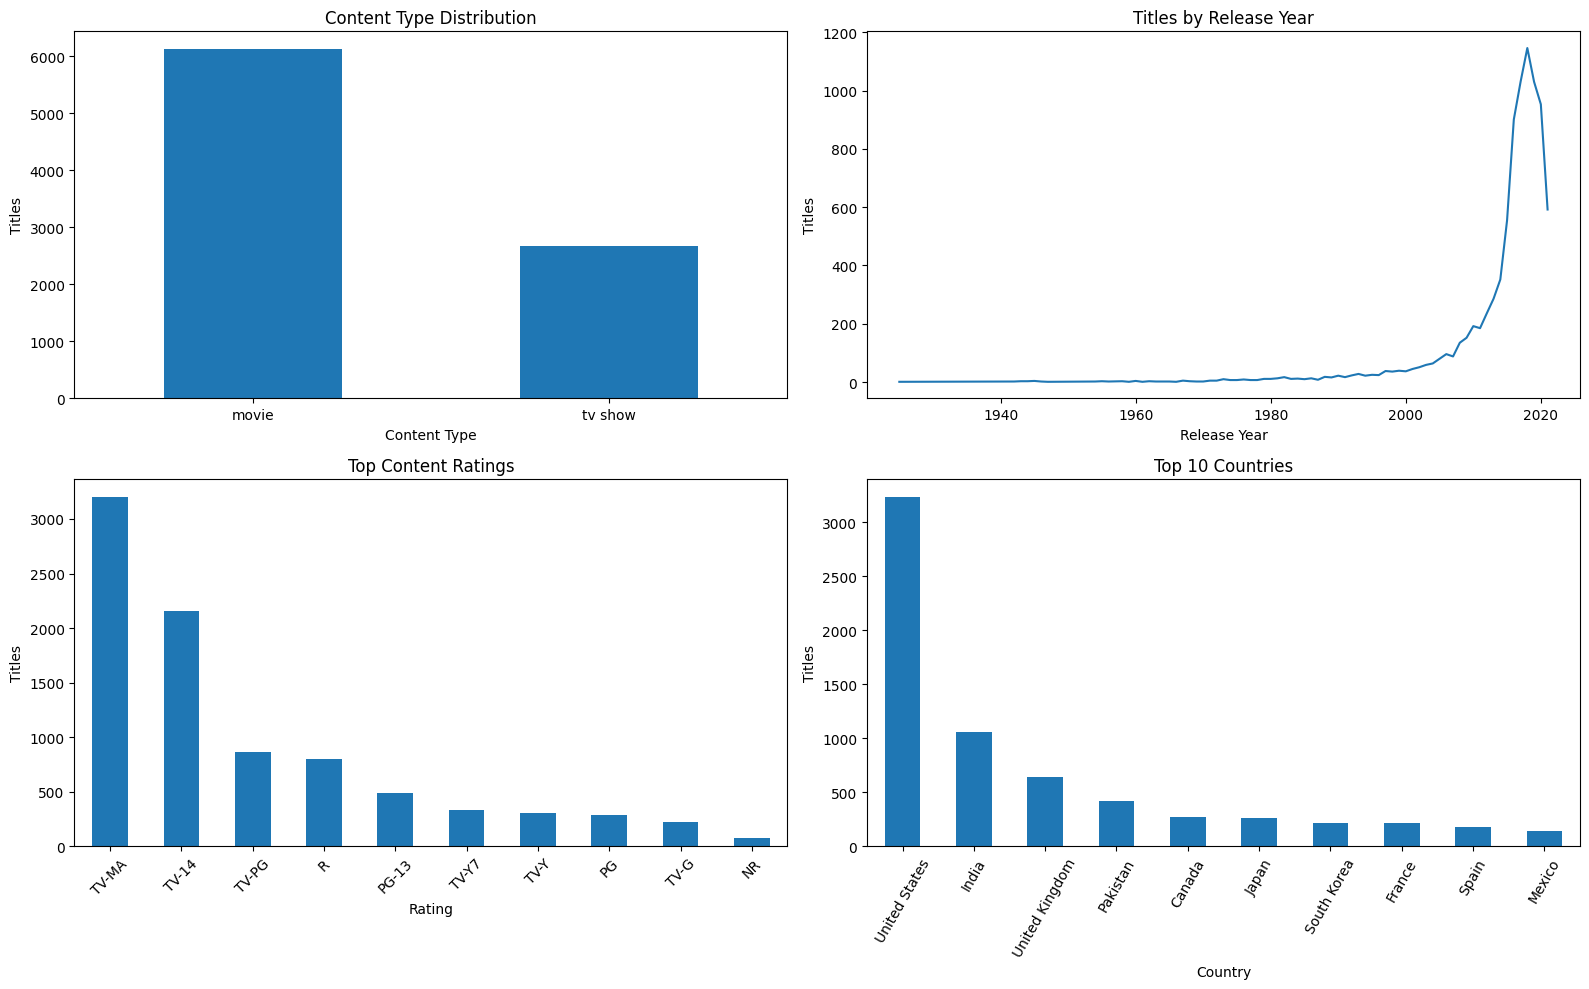

In [40]:
total_titles = analysis_df["show_id"].nunique()
total_movies = (analysis_df["type"] == "movie").sum()
total_tv_shows = (analysis_df["type"] == "tv show").sum()
unique_countries = country_counts.index.nunique()

print("=" * 55)
print("       NETFLIX BUSINESS INTELLIGENCE DASHBOARD")
print("=" * 55)

print(f"Total Titles       : {total_titles:,}")
print(f"Movies             : {total_movies:,}")
print(f"TV Shows           : {total_tv_shows:,}")
print(f"Countries Identified: {unique_countries:,}")
print("=" * 55)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Chart 1: Content types
content_counts.plot(
    kind="bar", ax=axes[0, 0], title="Content Type Distribution"
)
axes[0, 0].set_xlabel("Content Type")
axes[0, 0].set_ylabel("Titles")
axes[0, 0].tick_params(axis="x", rotation=0)

# Chart 2: Yearly trend
yearly_counts.plot(
    kind="line", ax=axes[0, 1], title="Titles by Release Year"
)
axes[0, 1].set_xlabel("Release Year")
axes[0, 1].set_ylabel("Titles")

# Chart 3: Ratings
rating_counts.plot(
    kind="bar", ax=axes[1, 0], title="Top Content Ratings"
)
axes[1, 0].set_xlabel("Rating")
axes[1, 0].set_ylabel("Titles")
axes[1, 0].tick_params(axis="x", rotation=45)

# Chart 4: Top countries
top_countries.plot(
    kind="bar", ax=axes[1, 1], title="Top 10 Countries"
)
axes[1, 1].set_xlabel("Country")
axes[1, 1].set_ylabel("Titles")
axes[1, 1].tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

### Interactive Content Exploration

An interactive chart is created using Plotly. It allows users to hover over data points and explore content counts by year and content type. Interactive visualizations make the dashboard easier to explore and support deeper analysis.

In [41]:
import plotly.express as px

interactive_yearly = (
    year_df.groupby(["release_year", "type"])["show_id"]
    .nunique()
    .reset_index(name="Number of Titles")
)

fig = px.line(
    interactive_yearly,
    x="release_year",
    y="Number of Titles",
    color="type",
    markers=True,
    title="Interactive Netflix Release-Year Trends",
    labels={
        "release_year": "Release Year",
        "Number of Titles": "Number of Titles",
        "type": "Content Type"
    },
    hover_data=["Number of Titles"]
)

fig.show()

## Step 4: Generate Actionable Business Insights

The dashboard helps identify how titles are distributed by content type, release year, rating, and country. These patterns can guide further investigation and support evidence-based planning.

### Potential Business Actions
1. **Content mix:** Review the balance between Movies and TV Shows when planning future analysis.
2. **Historical trends:** Investigate years with unusually high or low title counts.
3. **Ratings:** Examine rating categories to understand the classification profile of the catalog.
4. **Geographic representation:** Investigate countries with high or low representation.
5. **Further research:** Combine these findings with viewing hours, audience demographics, or subscription data before making investment decisions.

### Interpretation Limitation
The dataset describes the titles included in the supplied Netflix catalog snapshot. It does not contain direct viewer engagement, revenue, or audience demographic measures. Therefore, the findings describe catalog patterns rather than proving popularity, profitability, or audience demand.

In [42]:
print("NETFLIX BUSINESS INSIGHTS REPORT")
print("=" * 50)

print(f"Total distinct titles: {total_titles:,}")
print(f"Movies: {total_movies:,}")
print(f"TV Shows: {total_tv_shows:,}")

if total_titles:
    print(f"Movie share: {total_movies / total_titles * 100:.2f}%")
    print(f"TV Show share: {total_tv_shows / total_titles * 100:.2f}%")

print("\nTop 5 Ratings:")
display(rating_counts.head(5).reset_index(name="Number of Titles"))

print("\nTop 5 Countries:")
display(country_counts.head(5).reset_index(name="Number of Titles"))

print("\nRelease Year Summary:")
print("Earliest year:", int(year_df["release_year"].min()))
print("Latest year:", int(year_df["release_year"].max()))
print("Highest-count year:", int(yearly_counts.idxmax()))

print("\nBusiness Conclusion:")
print(
    "The dataset provides useful information about content mix, "
    "release-year distribution, ratings, and geographic representation. "
    "These findings can support further business analysis."
)

NETFLIX BUSINESS INSIGHTS REPORT
Total distinct titles: 8,790
Movies: 6,126
TV Shows: 2,664
Movie share: 69.69%
TV Show share: 30.31%

Top 5 Ratings:


,rating,Number of Titles
0,TV-MA,3205
1,TV-14,2157
2,TV-PG,861
3,R,799
4,PG-13,490



Top 5 Countries:


,country,Number of Titles
0,United States,3240
1,India,1057
2,United Kingdom,638
3,Pakistan,421
4,Canada,271



Release Year Summary:
Earliest year: 1925
Latest year: 2021
Highest-count year: 2018

Business Conclusion:
The dataset provides useful information about content mix, release-year distribution, ratings, and geographic representation. These findings can support further business analysis.


## Step 5: Final Analytical Report

### Executive Summary
This report presents an exploratory analysis of the provided Netflix dataset using Python. It examines content types, release years, ratings, and country-wise title representation. Visual dashboards are used to communicate the main patterns.

### Methodology
The dataset was loaded and inspected using Pandas. Data preparation included removing duplicate records from the analysis copy, standardizing selected text fields, and handling invalid release-year values. GroupBy operations and aggregations were used to calculate content distributions, and Matplotlib, Seaborn, and Plotly were used for visualization.

### Main Areas Analyzed
- Distribution of Movies and TV Shows
- Release-year trends
- Content rating categories
- Country-wise title representation
- Interactive and consolidated dashboards

### Business Recommendations
- Investigate historical changes in the title catalog.
- Review the balance of Movies and TV Shows.
- Examine rating and genre patterns for further audience research.
- Explore geographic representation in greater detail.
- Combine catalog analysis with viewing, revenue, and demographic data before making major business decisions.

### Conclusion
The Netflix Business Insights Report demonstrates an end-to-end data analysis workflow, from dataset preparation to visualization and reporting. It provides a structured overview of the supplied catalog and illustrates how data-driven analysis can support further business investigation.

### Limitations
The report is based only on the provided dataset. It does not establish actual Netflix production volumes, viewer preferences, revenue, or profitability. Any strategic decisions should be supported by additional business and audience data.

In [43]:
# Save important analysis tables
content_counts.rename("Number of Titles").to_csv(
    "content_type_summary.csv"
)

yearly_report = yearly_counts.reset_index()
yearly_report.columns = ["Release Year", "Number of Titles"]
yearly_report.to_csv("yearly_content_trend.csv", index=False)

rating_counts.reset_index(
    name="Number of Titles"
).to_csv("rating_summary.csv", index=False)

top_countries.reset_index(
    name="Number of Titles"
).to_csv("top_countries_report.csv", index=False)

print("Report tables exported successfully!")

files.download("content_type_summary.csv")
files.download("yearly_content_trend.csv")
files.download("rating_summary.csv")
files.download("top_countries_report.csv")

Report tables exported successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>